# DeepDream：是结构，还是训练数据？

同一张花卉、同一原版 GoogLeNet 特征提取结构、同一层和 175 步优化，比较 ImageNet 与 Places205 权重。随后分析此前 torchvision 随机网络为什么产生亮斑。

本 Notebook 读取已保存结果，不重新训练或下载权重。完整复跑命令：`python experiment.py`。

Feature extractors have identical architecture.
imagenet


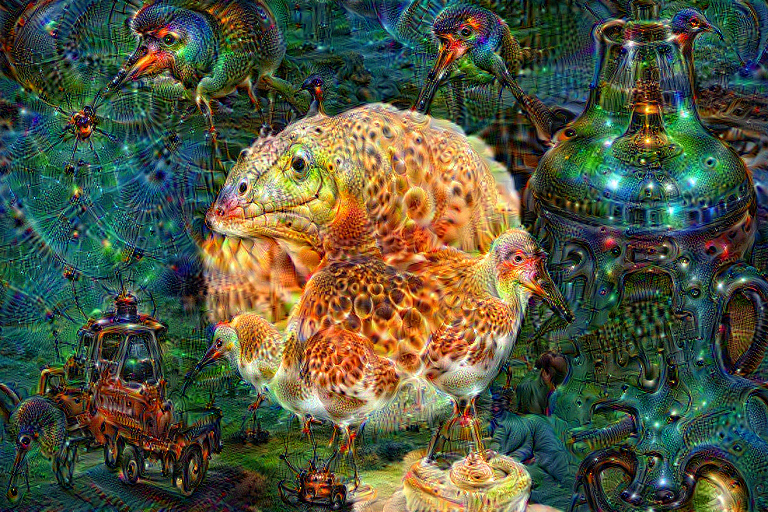

places205


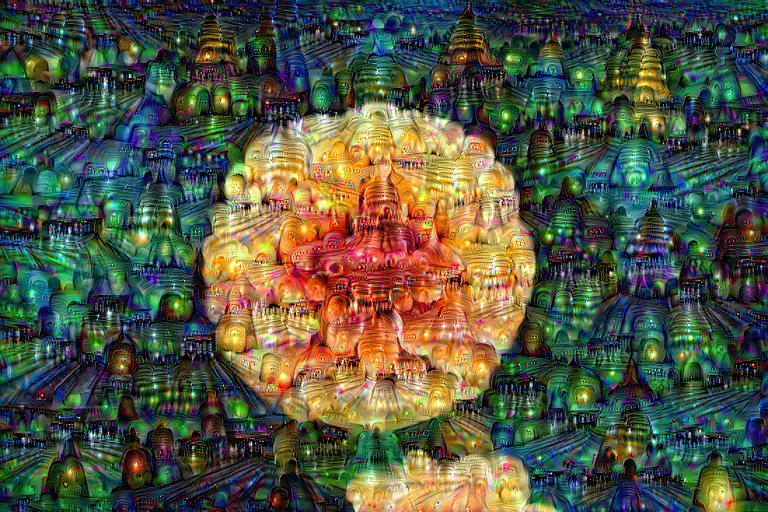

places205-native


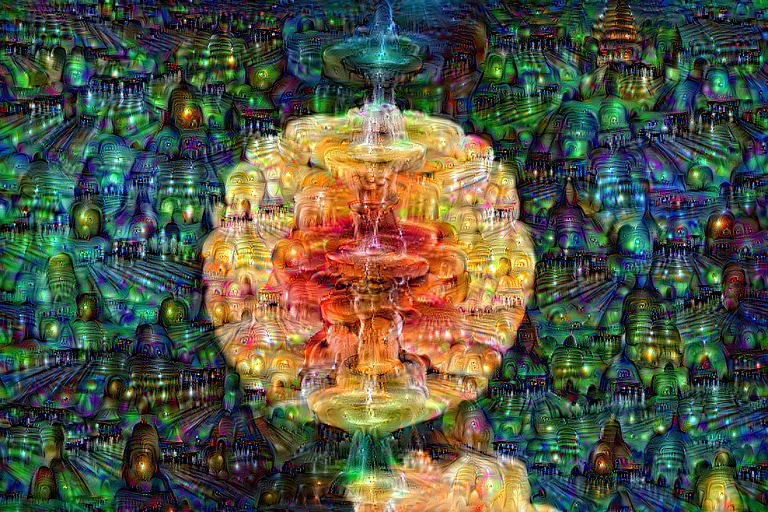

In [1]:
import json
from pathlib import Path
from IPython.display import display, Image
r = json.loads(Path('results/measurements.json').read_text())
assert r['identical_feature_architecture']
print('Feature extractors have identical architecture.')
for name in ['imagenet', 'places205', 'places205-native']:
    print(name)
    display(Image(filename=f'results/{name}.png', width=768))

ImageNet 结果有鸟头、眼睛与动物皮肤般斑纹；Places205 结果呈现塔尖、拱门与建筑般重复结构。主对照统一均值扣除，第三张使用 Places 原生均值。结构相同而内容改变，支持训练形成的特征影响形状。两份公开权重各自的训练过程也有差异。

## 随机权重仍然有响应

像素经过 $z=2x-1$，目标为 $J=\mathrm{mean}(f(z)^2)$。本实验随机初始化的网络满足正齐次性，因此 $J(tz)=t^2J(z)$。放大偏离中灰的信号即可增加目标。

检查 Euler 关系：$\sum(x-0.5)
abla_xJ=2J$。暗灰平均更新为负，亮灰为正；中灰的输入特征、目标和梯度都为零。

In [2]:
for seed in [42,43]:
    print(f'Random seed {seed}')
    probes = r[f'probes_{seed}']
    for value, row in probes.items():
        ratio = row['euler_ratio']
        if ratio is not None:
            assert abs(ratio-2) < 1e-4
        print(value, 'mean gradient:', round(row['mean_normalized_gradient'],6), 'Euler ratio:', ratio)
    assert probes['0.1']['mean_normalized_gradient'] < 0
    assert probes['0.9']['mean_normalized_gradient'] > 0
    assert probes['0.5']['energy'] == 0
print('All numerical checks passed.')

Random seed 42
0.1 mean gradient: -0.157696 Euler ratio: 2.000000238418579
0.3 mean gradient: -0.157696 Euler ratio: 2.000000476837158
0.5 mean gradient: 0.0 Euler ratio: None
0.7 mean gradient: 0.109603 Euler ratio: 2.000000238418579
0.9 mean gradient: 0.109603 Euler ratio: 2.000000238418579
flower mean gradient: -0.045594 Euler ratio: 1.9999998807907104
Random seed 43
0.1 mean gradient: -0.162001 Euler ratio: 1.9999998807907104
0.3 mean gradient: -0.162001 Euler ratio: 1.9999995231628418
0.5 mean gradient: 0.0 Euler ratio: None
0.7 mean gradient: 0.10635 Euler ratio: 2.000000238418579
0.9 mean gradient: 0.10635 Euler ratio: 2.000000238418579
flower mean gradient: -0.050438 Euler ratio: 2.0
All numerical checks passed.


random-42


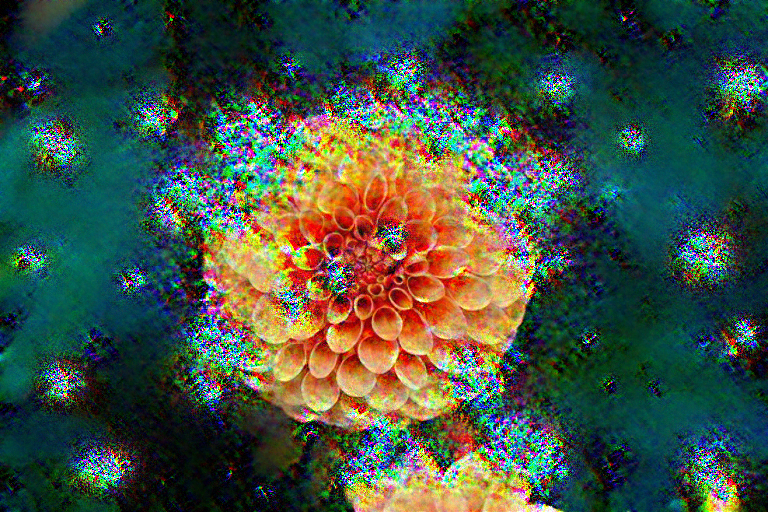

random-43


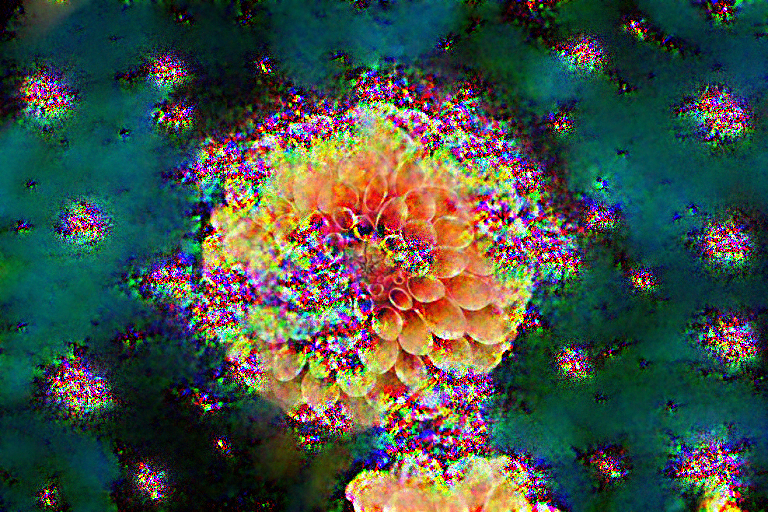

random-inverted


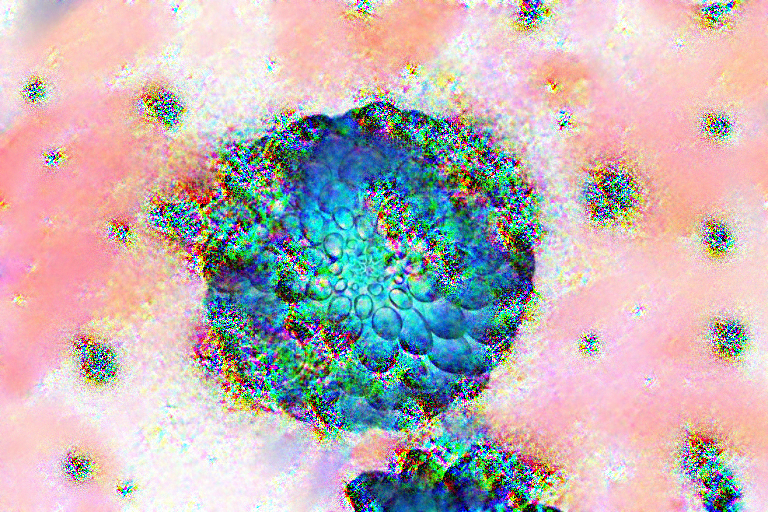

random-gray


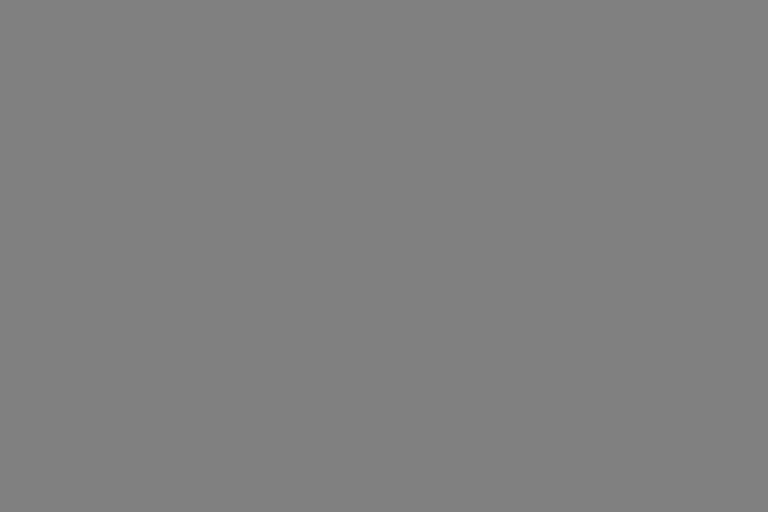

Original RGB statistics: {'mean': 0.24287885427474976, 'near_white_channels': 0.001330747501924634, 'near_black_channels': 0.15613900125026703}
Random seed 42 RGB statistics: {'mean': 0.27931350469589233, 'near_white_channels': 0.02179802767932415, 'near_black_channels': 0.10102759301662445}


In [3]:
for name in ['random-42','random-43','random-inverted','random-gray']:
    print(name)
    display(Image(filename=f'results/{name}.png', width=768))
print('Original RGB statistics:', r['original'])
print('Random seed 42 RGB statistics:', r['random_42']['stats'])
assert r['gray']['stats']['mean'] == .5

花形保留来自原图初始化及多尺度原图基底。随机网络会把响应放大到局部亮暗噪斑，像素截断将部分通道推到上下限。RGB 均值、上下限比例描述像素值，不等同于感知亮度。

## 来源

- [Google Inceptionism（2015）](https://research.google/blog/inceptionism-going-deeper-into-neural-networks/)：动物数据与 Places 场景数据生成不同梦境。
- [Feature Visualization（2017）](https://distill.pub/2017/feature-visualization/)：优化与高频梯度伪影。
- [权重转换实现](https://github.com/crowsonkb/pytorch-caffe-models)：固定版本见 requirements.txt。